In [ ]:
# Install/import standard data science & visualization packages
import gc
import math
import random
import statistics
import string
import time
import tracemalloc
from abc import ABC, abstractmethod
from dataclasses import dataclass, asdict
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configure clean publication-style plots
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120
print("Environment initialized successfully.")

Environment initialized successfully.


Cell 2: Data Models & Deterministic Workload Generator

In [ ]:
@dataclass
class Workload:
    name: str
    category: str          # "scaling_N", "scaling_M", "alphabet", "adversarial", "edge_case"
    alphabet_size: int
    text: str
    patterns: List[str]


@dataclass
class BenchmarkMetrics:
    algorithm: str
    workload_name: str
    category: str
    text_len: int
    pattern_len: int
    alphabet_size: int
    is_accurate: bool
    prep_time_us: float
    search_median_us: float
    search_p95_us: float
    search_iqr_us: float
    throughput_mb_s: float
    peak_memory_kb: float
    char_comparisons: int
    comparison_ratio_eta: float
    avg_shift_distance: float


class DatasetFactory:
    def __init__(self, seed: int = 42):
        self.rng = random.Random(seed)

    def generate_uniform(self, n: int, m: int, alphabet: str, name: str, category: str) -> Workload:
        text = "".join(self.rng.choices(alphabet, k=n))
        start = self.rng.randint(0, max(0, n - m))
        pattern = text[start : start + m]
        return Workload(name, category, len(set(alphabet)), text, [pattern])

    def generate_adversarial_periodic(self, n: int, m: int) -> Workload:
        """Triggers O(N*M) worst-case in Naive and degenerate shifts in Boyer-Moore."""
        text = "a" * n
        pattern = ("a" * (m - 1)) + "b"
        return Workload(f"Adversarial_N{n}_M{m}", "adversarial", 2, text, [pattern])

    def generate_overlapping_matches(self, n: int, m: int) -> Workload:
        """Verifies exact index parity on dense overlapping occurrences."""
        text = "a" * n
        pattern = "a" * m
        return Workload(f"Overlapping_N{n}_M{m}", "edge_case", 1, text, [pattern])

    def build_standard_suite(self) -> List[Workload]:
        suite = []
        # 1. Input-Size Scaling (N): 1KB to 500KB
        for n in [1_000, 5_000, 10_000, 50_000, 100_000, 250_000, 500_000]:
            suite.append(
                self.generate_uniform(n, 32, string.ascii_lowercase, f"ASCII_N{n}", "scaling_N")
            )

        # 2. Pattern-Size Scaling (M): 4 to 1024 on 100KB text
        for m in [4, 16, 64, 256, 1024]:
            suite.append(
                self.generate_uniform(100_000, m, string.printable[:90], f"Pattern_M{m}", "scaling_M")
            )

        # 3. Alphabet Size Impact (DNA |Σ|=4 vs Full ASCII |Σ|=90)
        suite.append(self.generate_uniform(100_000, 32, "ACGT", "DNA_Sigma4", "alphabet"))
        suite.append(self.generate_uniform(100_000, 32, string.printable[:90], "ASCII_Sigma90", "alphabet"))

        # 4. Pathological & Edge Cases
        suite.append(self.generate_adversarial_periodic(20_000, 200))
        suite.append(self.generate_overlapping_matches(5_000, 10))
        return suite

Cell 3: Pattern Matching Algorithms (Split Timing vs. Telemetry Modes)

In [ ]:
class BaseMatcher(ABC):
    @abstractmethod
    def preprocess(self, pattern: str) -> None:
        pass

    @abstractmethod
    def search(self, text: str) -> List[int]:
        pass

    @abstractmethod
    def search_instrumented(self, text: str) -> Tuple[List[int], int, int]:
        """Returns (match_indices, char_comparisons, total_shifts)."""
        pass


class NaiveMatcher(BaseMatcher):
    def __init__(self):
        self.pattern = ""

    def preprocess(self, pattern: str) -> None:
        self.pattern = pattern

    def search(self, text: str) -> List[int]:
        n, m = len(text), len(self.pattern)
        if m == 0 or m > n:
            return []
        matches = []
        for i in range(n - m + 1):
            j = 0
            while j < m and text[i + j] == self.pattern[j]:
                j += 1
            if j == m:
                matches.append(i)
        return matches

    def search_instrumented(self, text: str) -> Tuple[List[int], int, int]:
        n, m = len(text), len(self.pattern)
        if m == 0 or m > n:
            return [], 0, 0
        matches, comps, shifts = [], 0, 0
        for i in range(n - m + 1):
            shifts += 1
            j = 0
            while j < m:
                comps += 1
                if text[i + j] == self.pattern[j]:
                    j += 1
                else:
                    break
            if j == m:
                matches.append(i)
        return matches, comps, shifts


class KMPMatcher(BaseMatcher):
    def __init__(self):
        self.pattern = ""
        self.lps: List[int] = []

    def preprocess(self, pattern: str) -> None:
        self.pattern = pattern
        m = len(pattern)
        self.lps = [0] * m
        length = 0
        i = 1
        while i < m:
            if pattern[i] == pattern[length]:
                length += 1
                self.lps[i] = length
                i += 1
            elif length != 0:
                length = self.lps[length - 1]
            else:
                self.lps[i] = 0
                i += 1

    def search(self, text: str) -> List[int]:
        n, m = len(text), len(self.pattern)
        if m == 0 or m > n:
            return []
        matches = []
        i = j = 0
        while i < n:
            if self.pattern[j] == text[i]:
                i += 1
                j += 1
            if j == m:
                matches.append(i - j)
                j = self.lps[j - 1]
            elif i < n and self.pattern[j] != text[i]:
                if j != 0:
                    j = self.lps[j - 1]
                else:
                    i += 1
        return matches

    def search_instrumented(self, text: str) -> Tuple[List[int], int, int]:
        n, m = len(text), len(self.pattern)
        if m == 0 or m > n:
            return [], 0, 0
        matches, comps, shifts = [], 0, 0
        i = j = 0
        while i < n:
            comps += 1
            if self.pattern[j] == text[i]:
                i += 1
                j += 1
                if j == m:
                    matches.append(i - j)
                    shifts += 1
                    j = self.lps[j - 1]
            else:
                shifts += 1
                if j != 0:
                    j = self.lps[j - 1]
                else:
                    i += 1
        return matches, comps, shifts


class BoyerMooreHorspoolMatcher(BaseMatcher):
    def __init__(self):
        self.pattern = ""
        self.shift_table: Dict[str, int] = {}
        self.default_shift = 0

    def preprocess(self, pattern: str) -> None:
        self.pattern = pattern
        m = len(pattern)
        self.default_shift = m
        self.shift_table = {pattern[i]: m - 1 - i for i in range(m - 1)}

    def search(self, text: str) -> List[int]:
        n, m = len(text), len(self.pattern)
        if m == 0 or m > n:
            return []
        matches = []
        i = 0
        last = m - 1
        while i <= n - m:
            j = last
            while j >= 0 and self.pattern[j] == text[i + j]:
                j -= 1
            if j < 0:
                matches.append(i)
            i += self.shift_table.get(text[i + last], self.default_shift)
        return matches

    def search_instrumented(self, text: str) -> Tuple[List[int], int, int]:
        n, m = len(text), len(self.pattern)
        if m == 0 or m > n:
            return [], 0, 0
        matches, comps, shifts = [], 0, 0
        i = 0
        last = m - 1
        while i <= n - m:
            j = last
            while j >= 0:
                comps += 1
                if self.pattern[j] == text[i + j]:
                    j -= 1
                else:
                    break
            if j < 0:
                matches.append(i)
            i += self.shift_table.get(text[i + last], self.default_shift)
            shifts += 1
        return matches, comps, shifts


class RabinKarpMatcher(BaseMatcher):
    def __init__(self, base: int = 256, prime: int = 1_000_000_007):
        self.base = base
        self.prime = prime
        self.pattern = ""
        self.pattern_hash = 0
        self.high_order = 1

    def preprocess(self, pattern: str) -> None:
        self.pattern = pattern
        m = len(pattern)
        self.pattern_hash = 0
        self.high_order = pow(self.base, max(0, m - 1), self.prime)
        for ch in pattern:
            self.pattern_hash = (self.pattern_hash * self.base + ord(ch)) % self.prime

    def search(self, text: str) -> List[int]:
        n, m = len(text), len(self.pattern)
        if m == 0 or m > n:
            return []
        matches = []
        window_hash = 0
        for i in range(m):
            window_hash = (window_hash * self.base + ord(text[i])) % self.prime

        for i in range(n - m + 1):
            if window_hash == self.pattern_hash:
                if text[i : i + m] == self.pattern:
                    matches.append(i)
            if i < n - m:
                window_hash = (
                    (window_hash - ord(text[i]) * self.high_order) * self.base
                    + ord(text[i + m])
                ) % self.prime
        return matches

    def search_instrumented(self, text: str) -> Tuple[List[int], int, int]:
        n, m = len(text), len(self.pattern)
        if m == 0 or m > n:
            return [], 0, 0
        matches, comps, shifts = [], 0, 0
        window_hash = 0
        for i in range(m):
            window_hash = (window_hash * self.base + ord(text[i])) % self.prime

        for i in range(n - m + 1):
            shifts += 1
            comps += 1  # Hash comparison
            if window_hash == self.pattern_hash:
                # Character verification upon hash hit
                for j in range(m):
                    comps += 1
                    if text[i + j] != self.pattern[j]:
                        break
                else:
                    matches.append(i)
            if i < n - m:
                window_hash = (
                    (window_hash - ord(text[i]) * self.high_order) * self.base
                    + ord(text[i + m])
                ) % self.prime
        return matches, comps, shifts

Cell 4: Execution Harness & Power-Law Scaling Engine

In [ ]:
def ground_truth_oracle(text: str, pattern: str) -> List[int]:
    """Exact ground-truth oracle supporting overlapping occurrences."""
    if not pattern:
        return []
    indices = []
    start = 0
    while True:
        idx = text.find(pattern, start)
        if idx == -1:
            break
        indices.append(idx)
        start = idx + 1
    return indices


class BenchmarkHarness:
    def __init__(self, warmup: int = 3, iterations: int = 15):
        self.warmup = warmup
        self.iterations = iterations

    def run_single(self, matcher: BaseMatcher, workload: Workload) -> BenchmarkMetrics:
        pattern = workload.patterns[0]
        text = workload.text
        expected = ground_truth_oracle(text, pattern)

        # 1. Measure Peak Memory & Preprocessing Latency
        gc.collect()
        gc.disable()
        tracemalloc.start()
        t0 = time.perf_counter_ns()
        matcher.preprocess(pattern)
        t1 = time.perf_counter_ns()
        _, peak_bytes = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        prep_us = (t1 - t0) / 1e3

        # 2. Warmup & Telemetry Verification Pass
        for _ in range(self.warmup):
            matcher.search(text)
        actual, comps, shifts = matcher.search_instrumented(text)
        is_accurate = (actual == expected)

        # 3. Uninstrumented Wall-Clock Timing Runs
        samples_us = []
        for _ in range(self.iterations):
            ts = time.perf_counter_ns()
            matcher.search(text)
            te = time.perf_counter_ns()
            samples_us.append((te - ts) / 1e3)
        gc.enable()

        samples_us.sort()
        median_us = statistics.median(samples_us)
        p95_us = samples_us[int(0.95 * len(samples_us))]
        q25 = samples_us[len(samples_us) // 4]
        q75 = samples_us[(3 * len(samples_us)) // 4]

        throughput_mb_s = (len(text) / 1e6) / (median_us / 1e6) if median_us > 0 else 0.0
        avg_shift = (len(text) / shifts) if shifts > 0 else 0.0
        eta = comps / len(text) if len(text) > 0 else 0.0

        return BenchmarkMetrics(
            algorithm=matcher.__class__.__name__.replace("Matcher", ""),
            workload_name=workload.name,
            category=workload.category,
            text_len=len(text),
            pattern_len=len(pattern),
            alphabet_size=workload.alphabet_size,
            is_accurate=is_accurate,
            prep_time_us=prep_us,
            search_median_us=median_us,
            search_p95_us=p95_us,
            search_iqr_us=q75 - q25,
            throughput_mb_s=throughput_mb_s,
            peak_memory_kb=peak_bytes / 1024.0,
            char_comparisons=comps,
            comparison_ratio_eta=eta,
            avg_shift_distance=avg_shift,
        )

    def run_suite(self, matchers: List[BaseMatcher], workloads: List[Workload]) -> pd.DataFrame:
        records = []
        for wl in workloads:
            for matcher in matchers:
                res = self.run_single(matcher, wl)
                records.append(asdict(res))
        return pd.DataFrame(records)


def compute_power_law_exponents(df: pd.DataFrame) -> pd.DataFrame:
    """Fits log(T) = a + b * log(N) on scaling_N workloads to extract empirical exponent b."""
    sub = df[df["category"] == "scaling_N"]
    rows = []
    for algo, group in sub.groupby("algorithm"):
        xs = np.log(group["text_len"].values)
        ys = np.log(group["search_median_us"].values)
        slope_b, intercept_a = np.polyfit(xs, ys, 1)
        y_pred = slope_b * xs + intercept_a
        ss_res = np.sum((ys - y_pred) ** 2)
        ss_tot = np.sum((ys - np.mean(ys)) ** 2)
        r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else 1.0
        rows.append({
            "Algorithm": algo,
            "Empirical Complexity Exponent (b)": round(slope_b, 4),
            "R² Goodness-of-Fit": round(r2, 4),
            "Mean Efficiency Ratio (η = Comps/N)": round(group["comparison_ratio_eta"].mean(), 4),
            "Peak Throughput (MB/s)": round(group["throughput_mb_s"].max(), 2),
        })
    return pd.DataFrame(rows).sort_values("Empirical Complexity Exponent (b)")

Cell 5: Execute Benchmark & Verify Accuracy

In [ ]:
factory = DatasetFactory(seed=42)
workloads = factory.build_standard_suite()

matchers = [
    NaiveMatcher(),
    KMPMatcher(),
    BoyerMooreHorspoolMatcher(),
    RabinKarpMatcher(),
]

harness = BenchmarkHarness(warmup=3, iterations=15)
print(f"Running {len(matchers)} algorithms across {len(workloads)} workloads...")
df_results = harness.run_suite(matchers, workloads)

# 1. Global Accuracy Verification Gate
all_accurate = df_results["is_accurate"].all()
print(f"\n[ACCURACY GATE] 100% Index Parity Across All Workloads: {all_accurate}")
if not all_accurate:
    display(df_results[~df_results["is_accurate"]])

# 2. Power-Law Asymptotic Complexity Table
print("\n[ASYMPTOTIC SCALING & EFFICIENCY SUMMARY]")
df_scaling_summary = compute_power_law_exponents(df_results)
display(df_scaling_summary)

# 3. Adversarial & Edge-Case Breakdown
print("\n[ADVERSARIAL & EDGE-CASE DIAGNOSTICS]")
display(
    df_results[df_results["category"].isin(["adversarial", "edge_case", "alphabet"])][
        ["algorithm", "workload_name", "is_accurate", "search_median_us", "comparison_ratio_eta", "avg_shift_distance"]
    ].sort_values(["workload_name", "search_median_us"])
)

Running 4 algorithms across 16 workloads...

[ACCURACY GATE] 100% Index Parity Across All Workloads: True

[ASYMPTOTIC SCALING & EFFICIENCY SUMMARY]


,Algorithm,Empirical Complexity Exponent (b),R² Goodness-of-Fit,Mean Efficiency Ratio (η = Comps/N),Peak Throughput (MB/s)
0,BoyerMooreHorspool,0.9983,0.9776,0.0636,74.83
2,Naive,1.0170,0.9999,1.0414,8.78
1,KMP,1.0305,0.9905,1.0396,5.84
3,RabinKarp,1.0407,0.9894,1.0002,2.51



[ADVERSARIAL & EDGE-CASE DIAGNOSTICS]


,algorithm,workload_name,is_accurate,search_median_us,comparison_ratio_eta,avg_shift_distance
54,BoyerMooreHorspool,ASCII_Sigma90,True,1794.520,0.03754,27.100271
52,Naive,ASCII_Sigma90,True,25351.874,1.01106,1.000310
53,KMP,ASCII_Sigma90,True,36006.218,1.01094,1.000410
55,RabinKarp,ASCII_Sigma90,True,42221.866,1.00001,1.000310
58,BoyerMooreHorspool,Adversarial_N20000_M200,True,4767.058,0.99005,1.010050
57,KMP,Adversarial_N20000_M200,True,4770.487,1.99005,1.010050
59,RabinKarp,Adversarial_N20000_M200,True,8343.957,0.99005,1.010050
56,Naive,Adversarial_N20000_M200,True,366200.168,198.01000,1.010050
50,BoyerMooreHorspool,DNA_Sigma4,True,8057.516,0.37623,3.753754
48,Naive,DNA_Sigma4,True,15231.330,1.33121,1.000310


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Cell 6: Diagnostic Visualizations

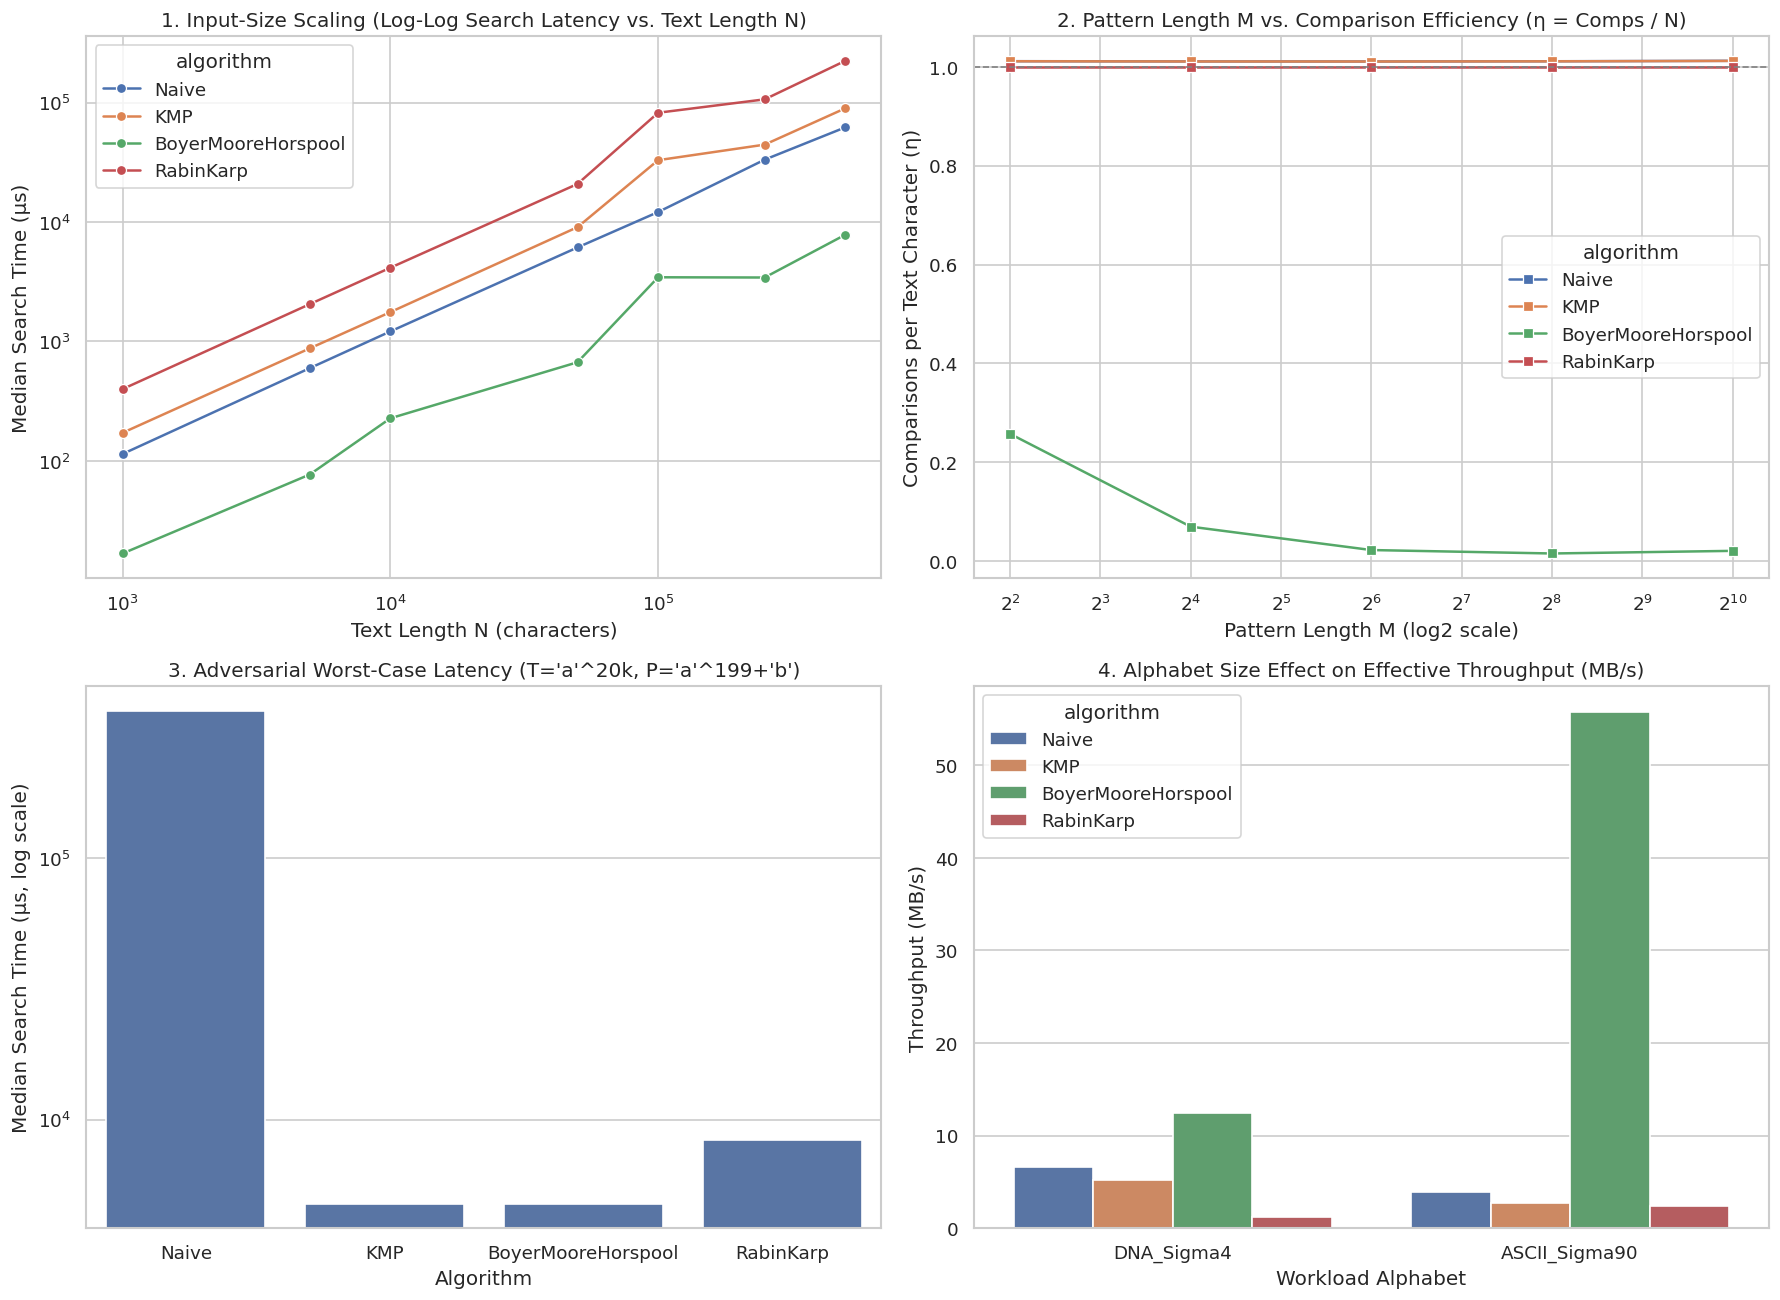

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Plot 1: Log-Log Input Size (N) Scaling
df_n = df_results[df_results["category"] == "scaling_N"]
sns.lineplot(
    data=df_n, x="text_len", y="search_median_us", hue="algorithm", marker="o", ax=axes[0, 0]
)
axes[0, 0].set_xscale("log")
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("1. Input-Size Scaling (Log-Log Search Latency vs. Text Length N)")
axes[0, 0].set_xlabel("Text Length N (characters)")
axes[0, 0].set_ylabel("Median Search Time (µs)")

# Plot 2: Pattern Length (M) Impact on Comparison Efficiency (η = Comps / N)
df_m = df_results[df_results["category"] == "scaling_M"]
sns.lineplot(
    data=df_m, x="pattern_len", y="comparison_ratio_eta", hue="algorithm", marker="s", ax=axes[0, 1]
)
axes[0, 1].set_xscale("log", base=2)
axes[0, 1].axhline(1.0, color="gray", linestyle="--", linewidth=1, label="Linear Scan (η = 1.0)")
axes[0, 1].set_title("2. Pattern Length M vs. Comparison Efficiency (η = Comps / N)")
axes[0, 1].set_xlabel("Pattern Length M (log2 scale)")
axes[0, 1].set_ylabel("Comparisons per Text Character (η)")

# Plot 3: Adversarial Worst-Case Comparison (Periodic Input)
df_adv = df_results[df_results["category"] == "adversarial"]
sns.barplot(
    data=df_adv, x="algorithm", y="search_median_us", ax=axes[1, 0]
)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("3. Adversarial Worst-Case Latency (T='a'^20k, P='a'^199+'b')")
axes[1, 0].set_xlabel("Algorithm")
axes[1, 0].set_ylabel("Median Search Time (µs, log scale)")

# Plot 4: Alphabet Size Impact (DNA |Σ|=4 vs Full ASCII |Σ|=90)
df_alpha = df_results[df_results["category"] == "alphabet"]
sns.barplot(
    data=df_alpha, x="workload_name", y="throughput_mb_s", hue="algorithm", ax=axes[1, 1]
)
axes[1, 1].set_title("4. Alphabet Size Effect on Effective Throughput (MB/s)")
axes[1, 1].set_xlabel("Workload Alphabet")
axes[1, 1].set_ylabel("Throughput (MB/s)")

plt.tight_layout()
plt.show()

Cell 7: Export Results to CSV

In [ ]:
output_filename = "pattern_matching_benchmark_results.csv"
df_results.to_csv(output_filename, index=False)
print(f"Saved {len(df_results)} benchmark records to '{output_filename}'.")

Saved 64 benchmark records to 'pattern_matching_benchmark_results.csv'.
